# Chapitre 3 - Cours 5 : Transactionnel ou analytique, et le stockage en colonnes

Ce notebook couvre la seconde moitié du chapitre : la section *Transaction Processing or
Analytics?* (*Data Warehousing*, *The divergence between OLTP databases and data
warehouses*, *Stars and Snowflakes: Schemas for Analytics*), la section *Column-Oriented
Storage* (*Column Compression*, *Memory bandwidth and vectorized processing*, *Sort
Order in Column Storage*, *Several different sort orders*, *Writing to Column-Oriented
Storage*) et la section *Aggregation: Data Cubes and Materialized Views*.

**Plan.**

1. Transactionnel ou analytique ? Les entrepôts de données et l'ETL.
2. Étoiles et flocons : les schémas pour l'analytique.
3. Le stockage orienté colonnes.
4. La compression des colonnes : dictionnaire, bitmaps, codage par plages.
5. Bande passante mémoire et traitement vectorisé.
6. L'ordre de tri dans un stockage en colonnes.
7. Écrire dans un stockage en colonnes.
8. Agrégation : vues matérialisées et cubes de données.

In [1]:
import gc
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
fact, dim_product, dim_date, dim_store = S.make_sales(500_000, n_extra_cols=12, seed=0)


def meilleur_temps(f, rep=5):
    """Meilleur temps (s) de `rep` exécutions, ramasse-miettes désactivé."""
    best = float("inf")
    for _ in range(rep):
        gc.disable()
        t0 = time.perf_counter()
        f()
        best = min(best, time.perf_counter() - t0)
        gc.enable()
    return best

## 1. Transactionnel ou analytique ? (section *Transaction Processing or Analytics?*)

Aux débuts des bases de données, une écriture correspondait à une **transaction
commerciale** (une vente, une commande, un salaire versé). Le mot est resté, même quand
les bases ont servi à tout autre chose : le schéma d'accès typique d'une application,
quelques lectures et écritures de lignes retrouvées par clé, s'appelle le **traitement
transactionnel en ligne** (*OLTP*). Mais les bases servent aussi à l'**analytique** :
des requêtes qui parcourent un très grand nombre de lignes, ne lisent que quelques
colonnes et calculent des agrégats (chiffre d'affaires par magasin et par mois, effet
d'une promotion...). Elles alimentent les rapports de **business intelligence** ; on
parle d'**OLAP** (*online analytic processing*).

In [2]:
pd.DataFrame({
    "Transactionnel (OLTP)": ["peu d'enregistrements par requête, retrouvés par clé",
                              "écritures aléatoires, faible latence, venant des utilisateurs",
                              "utilisateur final, via une application web",
                              "état le plus récent des données",
                              "de quelques Go à quelques To"],
    "Analytique (OLAP)": ["agrégats sur un très grand nombre d'enregistrements",
                          "imports en masse (ETL) ou flux d'événements",
                          "analyste interne, aide à la décision",
                          "historique des événements au fil du temps",
                          "de quelques To à quelques Po"],
}, index=["lectures", "écritures", "utilisé par", "données représentées", "volume"])

,Transactionnel (OLTP),Analytique (OLAP)
lectures,"peu d'enregistrements par requête, retrouvés p...",agrégats sur un très grand nombre d'enregistre...
écritures,"écritures aléatoires, faible latence, venant d...",imports en masse (ETL) ou flux d'événements
utilisé par,"utilisateur final, via une application web","analyste interne, aide à la décision"
données représentées,état le plus récent des données,historique des événements au fil du temps
volume,de quelques Go à quelques To,de quelques To à quelques Po


**Les entrepôts de données** (section *Data Warehousing*). Une entreprise a souvent des
dizaines de systèmes OLTP (site marchand, caisses, stocks, logistique, RH), chacun géré
par son équipe et tenu à une faible latence. Les administrateurs rechignent à y laisser
passer des requêtes analytiques coûteuses, qui dégraderaient les transactions. On copie
donc les données dans une base à part, l'**entrepôt de données** (*data warehouse*), en
lecture seule pour les analystes. La copie se fait par un processus d'**ETL** :
*extraire* les données des bases OLTP (export périodique ou flux continu de mises à
jour), les *transformer* en un schéma adapté à l'analyse (nettoyage, jointures), puis
les *charger* dans l'entrepôt.

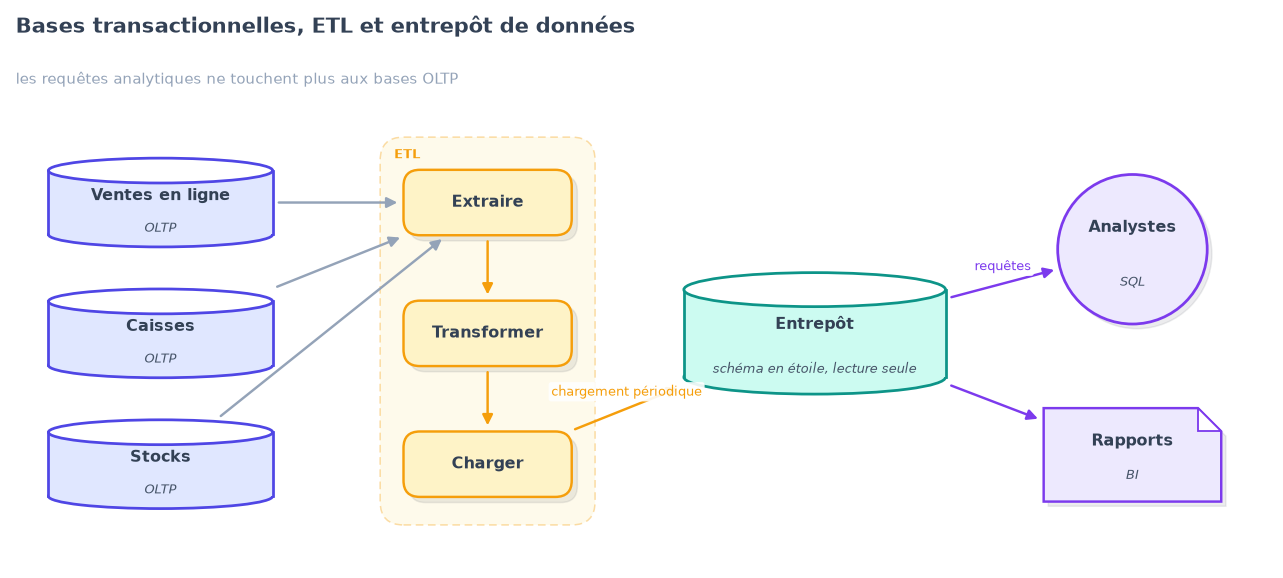

In [3]:
d = Diagram(13.5, 5.0, title="Bases transactionnelles, ETL et entrepôt de données",
            subtitle="les requêtes analytiques ne touchent plus aux bases OLTP")
for j, (nom, sub) in enumerate([("Ventes en ligne", "OLTP"), ("Caisses", "OLTP"), ("Stocks", "OLTP")]):
    d.box(f"o{j}", 1.6, 3.9 - j * 1.4, nom, sub=sub, color=INDIGO, kind="db", w=2.4, h=0.95)
d.box("e", 5.1, 3.9, "Extraire", color=AMBER, w=1.8, h=0.7)
d.box("t", 5.1, 2.5, "Transformer", color=AMBER, w=1.8, h=0.7)
d.box("l", 5.1, 1.1, "Charger", color=AMBER, w=1.8, h=0.7)
d.group(3.95, 0.45, 6.25, 4.6, "ETL", color=AMBER)
d.box("dw", 8.6, 2.5, "Entrepôt", sub="schéma en étoile, lecture seule", color=TEAL, kind="db", w=2.8, h=1.3)
d.box("bi", 12.0, 3.4, "Analystes", sub="SQL", color=VIOLET, kind="user", w=1.6)
d.box("rp", 12.0, 1.2, "Rapports", sub="BI", color=VIOLET, kind="doc", w=1.9, h=1.0)
for j in range(3):
    d.arrow(f"o{j}", "e", color=GRAY)
d.arrow("e", "t", color=AMBER); d.arrow("t", "l", color=AMBER)
d.arrow("l", "dw", "chargement périodique", color=AMBER)
d.arrow("dw", "bi", "requêtes", color=VIOLET); d.arrow("dw", "rp", color=VIOLET)
d.show()

**La divergence** (section *The divergence between OLTP databases and data
warehouses*). Le modèle de données d'un entrepôt est le plus souvent relationnel, car
SQL convient bien aux requêtes analytiques. En surface, entrepôt et base OLTP se
ressemblent donc (tous deux parlent SQL), mais leurs moteurs sont optimisés pour des
requêtes très différentes, et la plupart des éditeurs se spécialisent dans l'un ou
l'autre. C'est le sujet de la suite de ce cours : les index des cours 1 à 4 visent
l'OLTP, le stockage en colonnes vise l'analytique.

> **À retenir.** OLTP : beaucoup de petites requêtes par clé, sur l'état courant. OLAP :
> peu de grosses requêtes d'agrégation, sur l'historique. L'entrepôt de données, nourri
> par l'ETL, isole l'analytique des bases transactionnelles.